In [3]:
pip install numpy pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip



 BOOKSTORE INVENTORY SYSTEM
1. Show all books
2. Add a new book
3. Update a book
4. Remove a book
5. Record a sale
6. Generate analytics report
7. Create visualizations
8. Exit



Enter your choice (1-8):  7


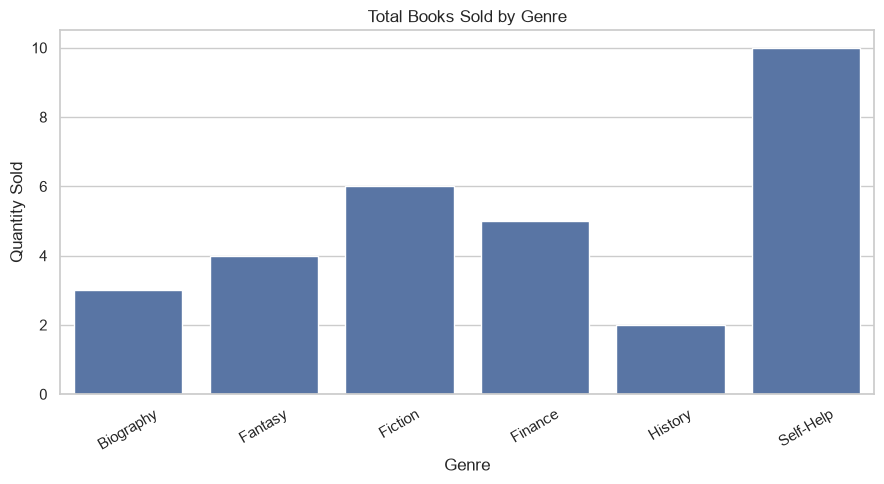

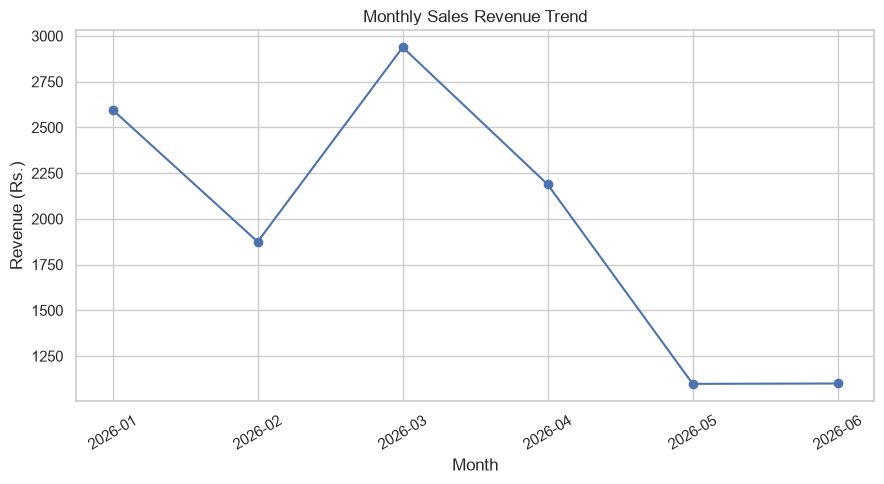

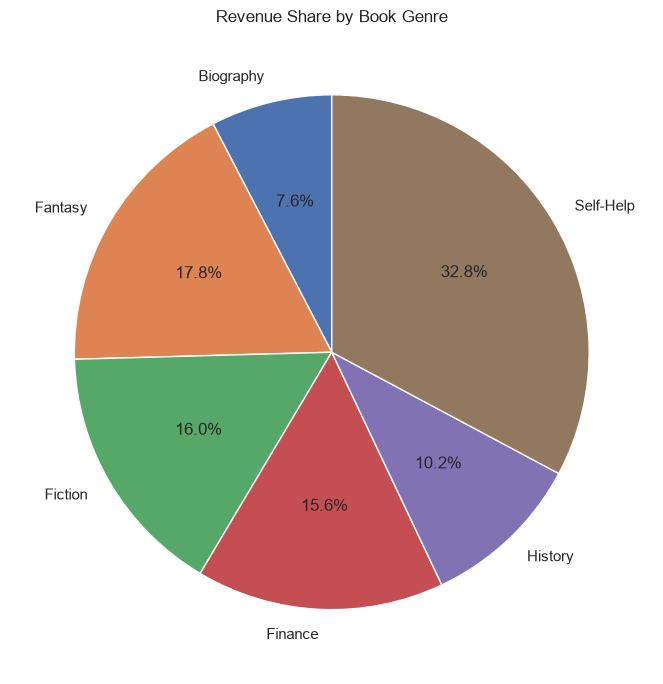

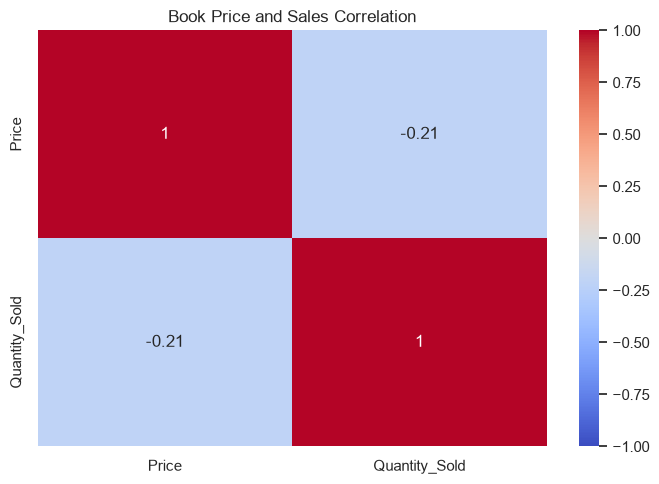

All charts saved inside charts folder!

 BOOKSTORE INVENTORY SYSTEM
1. Show all books
2. Add a new book
3. Update a book
4. Remove a book
5. Record a sale
6. Generate analytics report
7. Create visualizations
8. Exit



Enter your choice (1-8):  3
Book Title:  4
New Price:  6
New Quantity:  1


Error: Book not found.

 BOOKSTORE INVENTORY SYSTEM
1. Show all books
2. Add a new book
3. Update a book
4. Remove a book
5. Record a sale
6. Generate analytics report
7. Create visualizations
8. Exit



Enter your choice (1-8):  2
Book Title:  8
Author:  8
Genre:  8
Price:  99
Quantity:  4


Book added successfully!

 BOOKSTORE INVENTORY SYSTEM
1. Show all books
2. Add a new book
3. Update a book
4. Remove a book
5. Record a sale
6. Generate analytics report
7. Create visualizations
8. Exit



Enter your choice (1-8):  8


Thank you for using Bookstore System!


In [5]:

"""
Bookstore Inventory and Analytics System
Using Python, OOP, NumPy, Pandas, Matplotlib and Seaborn
"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = Path.cwd()

INVENTORY_FILE = BASE_DIR / "inventory.csv"
SALES_FILE = BASE_DIR / "sales.csv"


class Bookstore:

    def __init__(self):
        self.inventory = self.load_inventory()
        self.sales = self.load_sales()

    def load_inventory(self):
        if not INVENTORY_FILE.exists():
            pd.DataFrame(columns=[
                "Title", "Author", "Genre", "Price", "Quantity"
            ]).to_csv(INVENTORY_FILE, index=False)

        df = pd.read_csv(INVENTORY_FILE)

        for col in ["Title", "Author", "Genre", "Price", "Quantity"]:
            if col not in df.columns:
                df[col] = np.nan

        df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
        df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
        df = df.dropna(subset=["Title", "Price", "Quantity"])

        df["Title"] = df["Title"].astype(str).str.strip()
        df["Author"] = df["Author"].fillna("Unknown")
        df["Genre"] = df["Genre"].fillna("Uncategorized")

        df = df[
            (df["Title"] != "") &
            (df["Price"] > 0) &
            (df["Quantity"] >= 0)
        ]

        df["Quantity"] = df["Quantity"].astype(int)
        return df.reset_index(drop=True)

    def load_sales(self):
        if not SALES_FILE.exists():
            pd.DataFrame(columns=[
                "Date", "Title", "Quantity Sold", "Total Revenue"
            ]).to_csv(SALES_FILE, index=False)

        df = pd.read_csv(SALES_FILE)

        for col in ["Date", "Title", "Quantity Sold", "Total Revenue"]:
            if col not in df.columns:
                df[col] = np.nan

        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
        df["Quantity Sold"] = pd.to_numeric(
            df["Quantity Sold"], errors="coerce"
        )
        df["Total Revenue"] = pd.to_numeric(
            df["Total Revenue"], errors="coerce"
        )

        df = df.dropna(
            subset=["Date", "Title", "Quantity Sold", "Total Revenue"]
        )

        df = df[
            (df["Quantity Sold"] > 0) &
            (df["Total Revenue"] >= 0)
        ]

        df["Quantity Sold"] = df["Quantity Sold"].astype(int)
        return df.reset_index(drop=True)

    def save_inventory(self):
        self.inventory.to_csv(INVENTORY_FILE, index=False)

    def save_sales(self):
        df = self.sales.copy()
        df["Date"] = df["Date"].dt.strftime("%Y-%m-%d")
        df.to_csv(SALES_FILE, index=False)

    def add_book(self, title, author, genre, price, quantity):

        if not title.strip() or not author.strip() or not genre.strip():
            raise ValueError("Fields cannot be empty.")

        if price <= 0 or quantity < 0:
            raise ValueError("Invalid price or quantity.")

        exists = self.inventory["Title"].str.casefold() == title.casefold()

        if exists.any():
            raise ValueError("Book already exists.")

        new_book = {
            "Title": title,
            "Author": author,
            "Genre": genre,
            "Price": price,
            "Quantity": quantity
        }

        self.inventory.loc[len(self.inventory)] = new_book
        self.save_inventory()

        return "Book added successfully!"

    def update_book(self, title, price, quantity):

        matches = self.inventory["Title"].str.casefold() == title.casefold()

        if not matches.any():
            raise ValueError("Book not found.")

        if price <= 0 or quantity < 0:
            raise ValueError("Invalid price or quantity.")

        index = self.inventory.index[matches][0]

        self.inventory.at[index, "Price"] = price
        self.inventory.at[index, "Quantity"] = quantity

        self.save_inventory()

        return "Book updated successfully!"

    def remove_book(self, title):

        matches = self.inventory["Title"].str.casefold() == title.casefold()

        if not matches.any():
            raise ValueError("Book not found.")

        self.inventory = self.inventory.loc[~matches].reset_index(drop=True)
        self.save_inventory()

        return "Book removed successfully!"

    def record_sale(self, title, quantity):

        if quantity <= 0:
            raise ValueError("Quantity must be positive.")

        matches = self.inventory["Title"].str.casefold() == title.casefold()

        if not matches.any():
            raise ValueError("Book not found.")

        index = self.inventory.index[matches][0]
        stock = int(self.inventory.at[index, "Quantity"])

        if quantity > stock:
            raise ValueError(f"Only {stock} books available.")

        price = float(self.inventory.at[index, "Price"])
        revenue = price * quantity

        self.inventory.at[index, "Quantity"] = stock - quantity

        new_sale = {
            "Date": pd.Timestamp.today().normalize(),
            "Title": self.inventory.at[index, "Title"],
            "Quantity Sold": quantity,
            "Total Revenue": revenue
        }

        self.sales.loc[len(self.sales)] = new_sale

        self.save_inventory()
        self.save_sales()

        return f"Sale successful! Revenue: Rs. {revenue:.2f}"

    def show_inventory(self):

        print("\n========== BOOK INVENTORY ==========")

        if self.inventory.empty:
            print("Inventory is empty.")
        else:
            print(self.inventory.to_string(index=False))

    def generate_report(self):

        total_books = len(self.inventory)

        total_stock = np.sum(self.inventory["Quantity"])

        inventory_value = np.sum(
            self.inventory["Price"] * self.inventory["Quantity"]
        )

        total_sold = np.sum(self.sales["Quantity Sold"])

        total_revenue = np.sum(self.sales["Total Revenue"])

        average_price = (
            np.mean(self.inventory["Price"])
            if total_books > 0 else 0
        )

        print("\n========== SALES ANALYTICS REPORT ==========")

        print("Total Book Titles:", total_books)
        print("Total Stock:", total_stock)
        print("Inventory Value: Rs.", round(inventory_value, 2))
        print("Total Books Sold:", total_sold)
        print("Total Revenue: Rs.", round(total_revenue, 2))
        print("Average Book Price: Rs.", round(average_price, 2))

        if not self.sales.empty:

            best_seller = (
                self.sales.groupby("Title")["Quantity Sold"]
                .sum().idxmax()
            )

            print("Best Selling Book:", best_seller)

        else:
            print("No sales recorded yet.")

    def create_visualizations(self):

        if self.inventory.empty:
            print("Add books before creating visualizations.")
            return

        import os
        os.makedirs("charts", exist_ok=True)

        sns.set_theme(style="whitegrid")

        if self.sales.empty:
            print("No sales data available for charts.")
            return

        sales_data = self.sales.merge(
            self.inventory[["Title", "Genre", "Price"]],
            on="Title",
            how="left"
        )

        sales_data["Genre"] = sales_data["Genre"].fillna("Unknown")

        # 1. BAR CHART

        genre_sales = sales_data.groupby("Genre")["Quantity Sold"].sum()

        plt.figure(figsize=(9, 5))
        sns.barplot(x=genre_sales.index, y=genre_sales.values)

        plt.title("Total Books Sold by Genre")
        plt.xlabel("Genre")
        plt.ylabel("Quantity Sold")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.savefig("charts/sales_by_genre.png")
        plt.show()
        plt.close()

        # 2. LINE GRAPH

        monthly_sales = sales_data.copy()

        monthly_sales["Month"] = (
            monthly_sales["Date"].dt.to_period("M").astype(str)
        )

        monthly = monthly_sales.groupby("Month")["Total Revenue"].sum()

        plt.figure(figsize=(9, 5))
        plt.plot(monthly.index, monthly.values, marker="o")

        plt.title("Monthly Sales Revenue Trend")
        plt.xlabel("Month")
        plt.ylabel("Revenue (Rs.)")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.savefig("charts/monthly_sales_trend.png")
        plt.show()
        plt.close()

        # 3. PIE CHART

        genre_revenue = sales_data.groupby("Genre")["Total Revenue"].sum()

        plt.figure(figsize=(7, 7))
        plt.pie(
            genre_revenue.values,
            labels=genre_revenue.index,
            autopct="%1.1f%%",
            startangle=90
        )

        plt.title("Revenue Share by Book Genre")
        plt.tight_layout()
        plt.savefig("charts/revenue_by_genre.png")
        plt.show()
        plt.close()

        # 4. HEATMAP

        price_sales = sales_data.groupby("Title").agg(
            Price=("Price", "first"),
            Quantity_Sold=("Quantity Sold", "sum")
        )

        correlation = price_sales.corr(numeric_only=True)

        plt.figure(figsize=(7, 5))
        sns.heatmap(
            correlation,
            annot=True,
            cmap="coolwarm",
            vmin=-1,
            vmax=1
        )

        plt.title("Book Price and Sales Correlation")
        plt.tight_layout()
        plt.savefig("charts/price_sales_heatmap.png")
        plt.show()
        plt.close()

        print("All charts saved inside charts folder!")


def main():

    bookstore = Bookstore()

    while True:

        print("\n======================================")
        print(" BOOKSTORE INVENTORY SYSTEM")
        print("======================================")

        print("1. Show all books")
        print("2. Add a new book")
        print("3. Update a book")
        print("4. Remove a book")
        print("5. Record a sale")
        print("6. Generate analytics report")
        print("7. Create visualizations")
        print("8. Exit")

        choice = input("\nEnter your choice (1-8): ").strip()

        try:

            if choice == "1":

                bookstore.show_inventory()

            elif choice == "2":

                title = input("Book Title: ").strip()
                author = input("Author: ").strip()
                genre = input("Genre: ").strip()

                price = float(input("Price: "))
                quantity = int(input("Quantity: "))

                print(bookstore.add_book(
                    title, author, genre, price, quantity
                ))

            elif choice == "3":

                title = input("Book Title: ").strip()
                price = float(input("New Price: "))
                quantity = int(input("New Quantity: "))

                print(bookstore.update_book(
                    title, price, quantity
                ))

            elif choice == "4":

                title = input("Book Title: ").strip()

                print(bookstore.remove_book(title))

            elif choice == "5":

                title = input("Book Title: ").strip()
                quantity = int(input("Quantity Sold: "))

                print(bookstore.record_sale(title, quantity))

            elif choice == "6":

                bookstore.generate_report()

            elif choice == "7":

                bookstore.create_visualizations()

            elif choice == "8":

                print("Thank you for using Bookstore System!")
                break

            else:

                print("Invalid choice. Please select 1 to 8.")

        except (ValueError, TypeError) as error:
            print("Error:", error)

        except Exception as error:
            print("Something went wrong:", error)


if __name__ == "__main__":
    main()
